In [1]:
import pandas as pd
import numpy as np

In [2]:
#data = 'https://raw.githubusercontent.com/alexeygrigorev/mlbookcamp-code/master/chapter-02-car-price/data.csv'
#!wget $data

In [3]:
df = pd.read_csv('data.csv')

In [4]:
df.head()

,Make,Model,Year,Engine Fuel Type,Engine HP,Engine Cylinders,Transmission Type,Driven_Wheels,Number of Doors,Market Category,Vehicle Size,Vehicle Style,highway MPG,city mpg,Popularity,MSRP
0,BMW,1 Series M,2011,premium unleaded (required),335.0,6.0,MANUAL,rear wheel drive,2.0,"Factory Tuner,Luxury,High-Performance",Compact,Coupe,26,19,3916,46135
1,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,Performance",Compact,Convertible,28,19,3916,40650
2,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,High-Performance",Compact,Coupe,28,20,3916,36350
3,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,Performance",Compact,Coupe,28,18,3916,29450
4,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,Luxury,Compact,Convertible,28,18,3916,34500


In [5]:
# clean column header names
df.columns = df.columns.str.lower().str.replace(' ', '_')

In [6]:
df['make'].unique()

<StringArray>
[          'BMW',          'Audi',          'FIAT', 'Mercedes-Benz',
      'Chrysler',        'Nissan',         'Volvo',         'Mazda',
    'Mitsubishi',       'Ferrari',    'Alfa Romeo',        'Toyota',
       'McLaren',       'Maybach',       'Pontiac',       'Porsche',
          'Saab',           'GMC',       'Hyundai',      'Plymouth',
         'Honda',    'Oldsmobile',        'Suzuki',          'Ford',
      'Cadillac',           'Kia',       'Bentley',     'Chevrolet',
         'Dodge',   'Lamborghini',       'Lincoln',        'Subaru',
    'Volkswagen',        'Spyker',         'Buick',         'Acura',
   'Rolls-Royce',      'Maserati',         'Lexus',  'Aston Martin',
    'Land Rover',         'Lotus',      'Infiniti',         'Scion',
       'Genesis',        'HUMMER',         'Tesla',       'Bugatti']
Length: 48, dtype: str

In [7]:
# get categorical (string) columns
strings = list(df.dtypes[df.dtypes == 'str'].index)
strings

['make',
 'model',
 'engine_fuel_type',
 'transmission_type',
 'driven_wheels',
 'market_category',
 'vehicle_size',
 'vehicle_style']

In [8]:
import time

In [9]:
start_time = time.perf_counter()

for col in strings:
    df[col] = df[col].str.lower().str.replace(' ', '_')

end_time = time.perf_counter()
elapsed_time = end_time - start_time

print(f"Elapsed time: {elapsed_time:.6f} seconds")

Elapsed time: 0.066117 seconds


In [10]:
df.head()

,make,model,year,engine_fuel_type,engine_hp,engine_cylinders,transmission_type,driven_wheels,number_of_doors,market_category,vehicle_size,vehicle_style,highway_mpg,city_mpg,popularity,msrp
0,bmw,1_series_m,2011,premium_unleaded_(required),335.0,6.0,manual,rear_wheel_drive,2.0,"factory_tuner,luxury,high-performance",compact,coupe,26,19,3916,46135
1,bmw,1_series,2011,premium_unleaded_(required),300.0,6.0,manual,rear_wheel_drive,2.0,"luxury,performance",compact,convertible,28,19,3916,40650
2,bmw,1_series,2011,premium_unleaded_(required),300.0,6.0,manual,rear_wheel_drive,2.0,"luxury,high-performance",compact,coupe,28,20,3916,36350
3,bmw,1_series,2011,premium_unleaded_(required),230.0,6.0,manual,rear_wheel_drive,2.0,"luxury,performance",compact,coupe,28,18,3916,29450
4,bmw,1_series,2011,premium_unleaded_(required),230.0,6.0,manual,rear_wheel_drive,2.0,luxury,compact,convertible,28,18,3916,34500


In [11]:
start_time = time.perf_counter()

df[strings] = df[strings].apply(lambda x: x.str.lower().str.replace(' ', '_'))

end_time = time.perf_counter()

elapsed_time = end_time - start_time

print(f"Elapsed time {elapsed_time:.6f} seconds")

Elapsed time 0.087740 seconds


# 2.3 Exploratory data analysis

In [12]:
# 2.3 EDA
for col in df.columns:
    print(col)
    print(df[col].unique()[:5])
    print(df[col].nunique())
    print()

make
<StringArray>
['bmw', 'audi', 'fiat', 'mercedes-benz', 'chrysler']
Length: 5, dtype: str
48

model
<StringArray>
['1_series_m', '1_series', '100', '124_spider', '190-class']
Length: 5, dtype: str
914

year
[2011 2012 2013 1992 1993]
28

engine_fuel_type
<StringArray>
[   'premium_unleaded_(required)',               'regular_unleaded',
 'premium_unleaded_(recommended)',       'flex-fuel_(unleaded/e85)',
                         'diesel']
Length: 5, dtype: str
10

engine_hp
[335. 300. 230. 320. 172.]
356

engine_cylinders
[ 6.  4.  5.  8. 12.]
9

transmission_type
<StringArray>
['manual', 'automatic', 'automated_manual', 'direct_drive', 'unknown']
Length: 5, dtype: str
5

driven_wheels
<StringArray>
['rear_wheel_drive', 'front_wheel_drive', 'all_wheel_drive',
 'four_wheel_drive']
Length: 4, dtype: str
4

number_of_doors
[ 2.  4.  3. nan]
3

market_category
<StringArray>
['factory_tuner,luxury,high-performance',
                    'luxury,performance',
               'luxury,high-pe

In [13]:
# Distribution of price
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

<Axes: xlabel='msrp', ylabel='Count'>

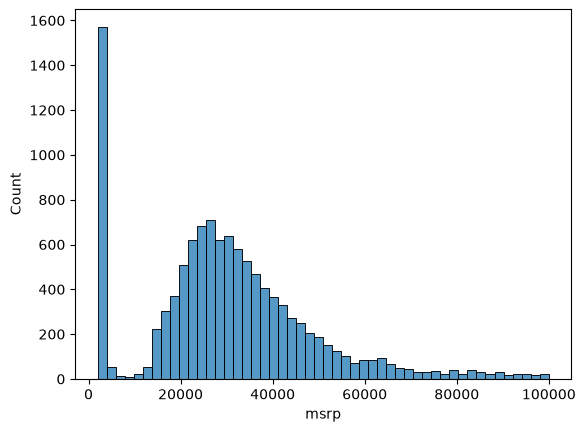

In [14]:
# display the long tailed distribution of MSRP
sns.histplot(df['msrp'][df['msrp'] < 100000], bins=50)

## Plot Notes
Long tailed distribution will confuse model.
Are there any outliers in the dataset? Could any of the cars with 1000 MSRP be considered an outlier? Could it be the default MSRP price?
Needed to zoom-in on the plot by filtering MSRP to less than 100,000.

In [15]:
# Apply log transform to deal with long tail
np.log([0 + 1, 1 + 1, 10 + 1, 1000 + 1, 100000 + 1])

array([ 0.        ,  0.69314718,  2.39789527,  6.90875478, 11.51293546])

In [16]:
np.log1p([0, 1, 10, 1000, 100000])

array([ 0.        ,  0.69314718,  2.39789527,  6.90875478, 11.51293546])

In [17]:
price_logs = np.log1p(df['msrp'])

<Axes: xlabel='msrp', ylabel='Count'>

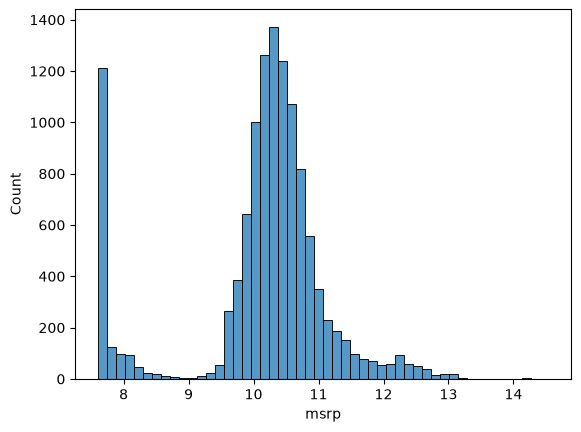

In [18]:
sns.histplot(price_logs, bins=50)

In [19]:
# Missing values
df.isnull().sum()

make                    0
model                   0
year                    0
engine_fuel_type        3
engine_hp              69
engine_cylinders       30
transmission_type       0
driven_wheels           0
number_of_doors         6
market_category      3742
vehicle_size            0
vehicle_style           0
highway_mpg             0
city_mpg                0
popularity              0
msrp                    0
dtype: int64

# 2.4 Setting Up The Validation Framework

In [20]:
n = len(df)

n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test # make sure len(df) == n_train + n_val + n_test

In [21]:
n, n_val + n_test + n_train

(11914, 11914)

In [22]:
n_val, n_test, n_train

(2382, 2382, 7150)

In [23]:
df_val = df.iloc[:n_val]
df_test = df.iloc[n_val:n_val+n_test]
df_train = df.iloc[n_val+n_test:]

In [24]:
idx = np.arange(n)

In [25]:
np.random.shuffle(idx)

In [26]:
idx

array([4495, 5891, 7555, ..., 6100, 5481, 1884], shape=(11914,))

In [27]:
df_train = df.iloc[idx[:n_train]]
df_val = df.iloc[idx[n_train:n_train+n_val]]
df_test = df.iloc[idx[n_train+n_val:]]

In [28]:
df.iloc[idx[:10]]

,make,model,year,engine_fuel_type,engine_hp,engine_cylinders,transmission_type,driven_wheels,number_of_doors,market_category,vehicle_size,vehicle_style,highway_mpg,city_mpg,popularity,msrp
4495,ford,f-150,2015,flex-fuel_(unleaded/e85),282.0,6.0,automatic,four_wheel_drive,2.0,flex_fuel,large,regular_cab_pickup,23,17,5657,34745
5891,subaru,impreza,2017,regular_unleaded,152.0,4.0,manual,all_wheel_drive,4.0,NaN,midsize,sedan,36,27,640,21995
7555,rolls-royce,phantom_coupe,2016,premium_unleaded_(required),453.0,12.0,automatic,rear_wheel_drive,2.0,"exotic,luxury,performance",large,coupe,19,11,86,449525
4109,cadillac,escalade_esv,2015,flex-fuel_(unleaded/e85),420.0,8.0,automatic,rear_wheel_drive,4.0,"flex_fuel,luxury,performance",large,4dr_suv,22,15,1624,84470
10787,subaru,tribeca,2012,regular_unleaded,256.0,6.0,automatic,all_wheel_drive,4.0,crossover,midsize,4dr_suv,21,16,640,35895
481,toyota,4runner,2014,regular_unleaded,270.0,6.0,automatic,four_wheel_drive,4.0,NaN,midsize,4dr_suv,22,17,2031,37615
1975,chevrolet,blazer,2004,regular_unleaded,190.0,6.0,automatic,four_wheel_drive,4.0,NaN,midsize,4dr_suv,17,13,1385,27230
10416,volkswagen,tiguan,2016,premium_unleaded_(recommended),200.0,4.0,automatic,all_wheel_drive,4.0,crossover,compact,4dr_suv,26,20,873,36420
2309,gmc,canyon,2016,regular_unleaded,305.0,6.0,automatic,four_wheel_drive,4.0,diesel,compact,crew_cab_pickup,24,17,549,34720
7976,audi,r8,2014,premium_unleaded_(required),525.0,10.0,automated_manual,all_wheel_drive,2.0,"luxury,high-performance",compact,coupe,22,13,3105,160300


In [29]:
len(df_train), len(df_val), len(df_test)

(7150, 2382, 2382)

In [30]:
# reset index
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

In [31]:
y_train = np.log1p(df_train['msrp'].values)
y_val = np.log1p(df_val['msrp'].values)
y_test = np.log1p(df_test['msrp'].values)

In [32]:
del df_train['msrp']
del df_val['msrp']
del df_test['msrp']

# 2.5 Linear Regression

In [33]:
df_train.iloc[10]

make                       land_rover
model                      freelander
year                             2005
engine_fuel_type     regular_unleaded
engine_hp                       174.0
engine_cylinders                  6.0
transmission_type           automatic
driven_wheels         all_wheel_drive
number_of_doors                   2.0
market_category      crossover,luxury
vehicle_size                  compact
vehicle_style                 2dr_suv
highway_mpg                        19
city_mpg                           16
popularity                        258
Name: 10, dtype: object

In [34]:
xi = [456, 19, 617]

In [35]:
w0 = 7.17
w = [0.01, 0.04, 0.002]

In [36]:
def linear_regression(xi):
    n = len(xi)
    pred = w0
    for j in range(n):
        pred = pred + w[j] * xi[j]

    return pred

In [37]:
linear_regression(xi)

13.724

In [38]:
y_train[10]

np.float64(10.197313214435868)

In [39]:
np.expm1(linear_regression(xi))

np.float64(912550.6814130992)

In [40]:
np.expm1(y_train[10])

np.float64(26829.999999999978)

In [41]:
np.expm1(y_train[:11])

array([ 34745.,  21995., 449525.,  84470.,  35895.,  37615.,  27230.,
        36420.,  34720., 160300.,  26830.])

# 2.6 Linear Regression: Vector Form

In [42]:
def dot(xi, w):
    n = len(xi)
    res = 0.0

    for j in range(n):
        res = res + xi[j] * w[j]

    return  res

In [43]:
def linear_regression(xi):
    return w0 + dot(xi, w)

In [44]:
w_new = [w0] + w
w_new

[7.17, 0.01, 0.04, 0.002]

In [45]:
def linear_regression(xi):
    xi = [1] + xi
    return dot(xi, w_new)

In [46]:
linear_regression(xi)

13.724

In [47]:
x1 = [1, 456, 19, 617]
x2 = [1, 400, 22, 1000]
x10 = [1, 453, 11, 86]

X = [x1, x2, x10]
X = np.array(X)

In [48]:
X.dot(w_new)

array([13.724, 14.05 , 12.312])

In [49]:
def linear_regression(X):
    return X.dot(w_new)

In [50]:
linear_regression(X)

array([13.724, 14.05 , 12.312])

# 2.7 Training Linear Regression: Normal Equation

In [51]:
X

array([[   1,  456,   19,  617],
       [   1,  400,   22, 1000],
       [   1,  453,   11,   86]])

In [52]:
X = [
    [456,   19,  617],
    [400,   22, 1000],
    [453,   11,   86]
]


X = np.array(X)
ones = np.ones(X.shape[0])
X = np.column_stack([ones, X])
y = np.array([100, 200, 150])

In [53]:
XTX = X.T.dot(X)
XTX_inv = np.linalg.inv(XTX)


In [54]:
w_full = XTX_inv.dot(X.T).dot(y)

In [55]:
w_0 = w_full[0]
w = w_full[1:]

w_0, w

(np.float64(2085.302734375), array([-4.89788055,  9.47875977, -0.25892258]))

In [56]:
def train_linear_regression(X, y):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)

    return w_full[0], w_full[1:]

In [57]:
X = [
    [456,   19,  617],
    [400,   22, 1000],
    [453,   11,   86]
]
X = np.array(X)
train_linear_regression(X, y)

(np.float64(2085.302734375), array([-4.89788055,  9.47875977, -0.25892258]))

# 2.8 Car price baseline model

In [58]:
df_train.dtypes

make                     str
model                    str
year                   int64
engine_fuel_type         str
engine_hp            float64
engine_cylinders     float64
transmission_type        str
driven_wheels            str
number_of_doors      float64
market_category          str
vehicle_size             str
vehicle_style            str
highway_mpg            int64
city_mpg               int64
popularity             int64
dtype: object

In [59]:
base = ['engine_hp', 'engine_cylinders', 'highway_mpg', 'city_mpg', 'popularity']

X_train = df_train[base].fillna(0).values

In [60]:
w0, w = train_linear_regression(X_train, y_train)

In [61]:
y_pred = w0 + X_train.dot(w)

<Axes: ylabel='Count'>

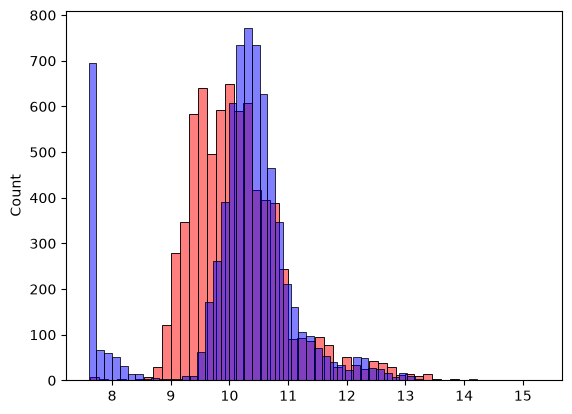

In [62]:
sns.histplot(y_pred, color='red', alpha=0.5, bins=50)
sns.histplot(y_train, color='blue', alpha=0.5, bins=50)

# 2.9 RMSE

In [63]:
def rmse(y, y_pred):
    se =  (y - y_pred) ** 2
    mse = se.mean()
    return np.sqrt(mse)

# 2.9 Validating the model

In [64]:
def prepare_X(df):
    df = df.copy()

    df['age'] = 2017 - df['year']
    features = base + ['age']
    
    df_num = df[features]
    df_num = df_num.fillna(0)
    
    return df_num.values

In [65]:
X_train = prepare_X(df_train)
w0, w = train_linear_regression(X_train, y_train)

X_val = prepare_X(df_val)
y_pred = w0 + X_val.dot(w)

rmse(y_val, y_pred)

np.float64(0.523739184475021)

In [66]:
w0, w

(np.float64(9.30921698897781),
 array([ 3.70769538e-03,  8.14199300e-02, -3.26637089e-03,  1.07947158e-02,
        -4.88110925e-05, -9.26990135e-02]))

# 2.11 Simple Feature Engineering

In [67]:
2017 - df_train.year

0       2
1       0
2       1
3       2
4       5
       ..
7145    1
7146    1
7147    4
7148    1
7149    5
Name: year, Length: 7150, dtype: int64

<Axes: ylabel='Count'>

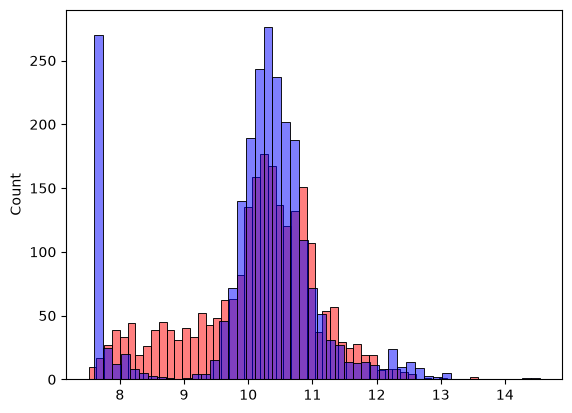

In [68]:
# plot improvement
sns.histplot(y_pred, color='red', alpha=0.5, bins=50)
sns.histplot(y_val, color='blue', alpha=0.5, bins=50)

# 2.12 Categorical Variables

In [69]:
makes = list(df['make'].value_counts().head().index)

In [70]:
df_train.dtypes

make                     str
model                    str
year                   int64
engine_fuel_type         str
engine_hp            float64
engine_cylinders     float64
transmission_type        str
driven_wheels            str
number_of_doors      float64
market_category          str
vehicle_size             str
vehicle_style            str
highway_mpg            int64
city_mpg               int64
popularity             int64
dtype: object

In [71]:
categorical_variables = [
    'make', 'engine_fuel_type', 'transmission_type', 'driven_wheels',
    'market_category', 'vehicle_size', 'vehicle_style'
]

In [72]:
categories = {}

for c in categorical_variables:
    categories[c] = list(df[c].value_counts().head().index)

In [73]:
categories

{'make': ['chevrolet', 'ford', 'volkswagen', 'toyota', 'dodge'],
 'engine_fuel_type': ['regular_unleaded',
  'premium_unleaded_(required)',
  'premium_unleaded_(recommended)',
  'flex-fuel_(unleaded/e85)',
  'diesel'],
 'transmission_type': ['automatic',
  'manual',
  'automated_manual',
  'direct_drive',
  'unknown'],
 'driven_wheels': ['front_wheel_drive',
  'rear_wheel_drive',
  'all_wheel_drive',
  'four_wheel_drive'],
 'market_category': ['crossover',
  'flex_fuel',
  'luxury',
  'luxury,performance',
  'hatchback'],
 'vehicle_size': ['compact', 'midsize', 'large'],
 'vehicle_style': ['sedan',
  '4dr_suv',
  'coupe',
  'convertible',
  '4dr_hatchback']}

In [74]:
def prepare_X(df):
    df = df.copy()
    features = base.copy()

    df['age'] = 2017 - df['year']
    features.append('age')

    for v in [2, 3, 4]:
        df[f'num_doors_{v}'] = (df['number_of_doors'] == v).astype('int')
        features.append(f'num_doors_{v}')
    for c, values in categories.items():
        for v in values:
            df[f'{c}_{v}'] = (df[c] == v).astype('int')
            features.append(f'{c}_{v}')
            
    df_num = df[features]
    df_num = df_num.fillna(0)
    
    return df_num.values

In [75]:
X_train = prepare_X(df_train)
w0, w = train_linear_regression(X_train, y_train)

X_val = prepare_X(df_val)
y_pred = w0 + X_val.dot(w)

rmse(y_val, y_pred)

np.float64(3368.0385738636937)

In [76]:
w

array([ 5.40023676e+00, -1.27321258e+02,  3.24942554e+01,  6.53908579e+01,
        5.05597663e-02,  3.96770090e+01,  1.64151802e+05,  1.64525935e+05,
        1.63986716e+05, -6.97445670e+01, -2.57036748e+02,  1.38397389e+02,
       -1.62753664e+02,  1.67785340e+01,  3.63623555e+03,  3.45500911e+03,
        3.81056962e+03,  3.63525043e+03,  2.94063461e+03,  8.11639911e+16,
        8.11639911e+16,  8.11639911e+16,  8.11639911e+16,  8.11639911e+16,
        6.07362568e+16,  6.07362568e+16,  6.07362568e+16,  6.07362568e+16,
        1.54907590e+01,  3.14220772e+01,  1.69368250e+01, -5.14207176e+01,
       -9.41605955e+00, -7.28844184e+01, -5.19807292e+01, -2.93353079e+01,
       -5.90695534e-02,  5.29223544e-02,  1.50330753e-01,  3.09712160e-01,
       -1.38698911e-01])

Adding more variables made the model worse. (Drastically increased RMSE.)

# 2.13 Regularization

In [89]:
X = [
    [4, 4, 4],
    [3, 5, 5],
    [5, 1, 1],
    [5, 4, 4],
    [7, 5, 5],
    [4, 5, 5.0000000125]
]

X = np.array(X)
X

array([[4.        , 4.        , 4.        ],
       [3.        , 5.        , 5.        ],
       [5.        , 1.        , 1.        ],
       [5.        , 4.        , 4.        ],
       [7.        , 5.        , 5.        ],
       [4.        , 5.        , 5.00000001]])

In [93]:
y = [1, 2, 3, 1, 2, 3]

In [90]:
XTX = X.T.dot(X)

In [92]:
XTX_inv = np.linalg.inv(XTX)

In [94]:
XTX_inv.dot(X.T).dot(y)

array([ 1.86704585e-01,  1.10273288e+06, -1.10273279e+06])

In [108]:
X = [
    [1, 2, 2],
    [2, 1, 1.0000001],
    [2, 1.0000001, 1]
]

XTX = np.array(XTX) 

In [109]:
np.linalg.inv(XTX)

array([[ 3.85624712e-02, -1.98159355e-02, -1.98158806e-02],
       [-1.98159355e-02,  5.00124975e+01, -4.99875026e+01],
       [-1.98158806e-02, -4.99875026e+01,  5.00124974e+01]])

In [112]:
XTX = XTX + 0.05 * np.eye(3)

In [113]:
np.linalg.inv(XTX)

array([[ 0.03842662, -0.01974062, -0.01974061],
       [-0.01974062,  7.15531241, -7.13040188],
       [-0.01974061, -7.13040188,  7.1553124 ]])

In [115]:
def train_linear_regression_reg(X, y, r=0.01):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX = XTX + r * np.eye(XTX.shape[0])

    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)

    return w_full[0], w_full[1:]

In [116]:
X_train = prepare_X(df_train)
w0, w = train_linear_regression_reg(X_train, y_train)

X_val = prepare_X(df_val)
y_pred = w0 + X_val.dot(w)

rmse(y_val, y_pred)

np.float64(0.4691082123761813)

# 2.14 Tuning the Model

In [117]:
for r in [0.0, 0.00001, 0.0001, 0.001, 0.1, 1, 10]:
    X_train = prepare_X(df_train)
    w0, w = train_linear_regression_reg(X_train, y_train, r=r)

    X_val = prepare_X(df_val)
    y_pred = w0 + X_val.dot(w)
    score = rmse(y_val, y_pred)

    print(r, w0, score)

0.0 -1.4190024791705088e+17 3368.0385738636937
1e-05 10.213969078345388 0.46909792640141984
0.0001 6.200359663399721 0.4690980435412541
0.001 6.243559890546961 0.46909895493844556
0.1 6.091324418440308 0.4692188796005878
1 5.409696639680839 0.4705993706138755
10 4.205754799701011 0.48338886672573894


In [121]:
r = 0.00001
X_train = prepare_X(df_train)
w0, w = train_linear_regression_reg(X_train, y_train, r=r)

X_val = prepare_X(df_val)
y_pred = w0 + X_val.dot(w)

rmse(y_val, y_pred)

np.float64(0.46909792640141984)

# 2.15 Using the model

In [122]:
df_full_train = pd.concat([df_train, df_val])
df_full_train = df_full_train.reset_index(drop=True)

X_full_train = prepare_X(df_full_train)

In [125]:
y_full_train = np.concatenate([y_train, y_val])

In [126]:
w0, w = train_linear_regression_reg(X_full_train, y_full_train, r=0.001)

In [129]:
X_test = prepare_X(df_test)
y_pred = w0 + X_test.dot(w)

rmse(y_test, y_pred)

np.float64(0.4494882826271367)

In [130]:
car = df_test.iloc[20].to_dict()
car

{'make': 'ford',
 'model': 'fusion_hybrid',
 'year': 2016,
 'engine_fuel_type': 'regular_unleaded',
 'engine_hp': 188.0,
 'engine_cylinders': 4.0,
 'transmission_type': 'automatic',
 'driven_wheels': 'front_wheel_drive',
 'number_of_doors': 4.0,
 'market_category': 'hybrid',
 'vehicle_size': 'midsize',
 'vehicle_style': 'sedan',
 'highway_mpg': 41,
 'city_mpg': 44,
 'popularity': 5657}

In [131]:
df_small = pd.DataFrame([car])
df_small

,make,model,year,engine_fuel_type,engine_hp,engine_cylinders,transmission_type,driven_wheels,number_of_doors,market_category,vehicle_size,vehicle_style,highway_mpg,city_mpg,popularity
0,ford,fusion_hybrid,2016,regular_unleaded,188.0,4.0,automatic,front_wheel_drive,4.0,hybrid,midsize,sedan,41,44,5657


In [134]:
X_small = prepare_X(df_small)

In [136]:
y_pred = w0 + X_small.dot(w)
y_pred = y_pred[0]